In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

# Download dataset
url = (
    "https://raw.githubusercontent.com/"
    "allisonhorst/palmerpenguins/main/"
    "inst/extdata/penguins.csv"
)

df = pd.read_csv(url)

# Display dataset
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [2]:
# Dataset information
df.info()

# Statistical summary
display(df.describe())

# Categorical variable summary
display(df.describe(include="object"))

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Species distribution
print("\nSpecies Distribution:")
print(df["species"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


,species,island,sex
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,male
freq,152,168,168



Missing Values:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Duplicate Records: 0

Species Distribution:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


In [3]:
# Create a cleaned dataset
clean_df = df.drop_duplicates().copy()

# Missing value analysis
missing_percentage = (
    clean_df.isnull().mean() * 100
).sort_values(ascending=False)

print("Missing Value Percentage:")
print(missing_percentage)

# Complete observations for core numerical analysis
analysis_df = clean_df.dropna(
    subset=[
        "species",
        "island",
        "bill_length_mm",
        "bill_depth_mm",
        "flipper_length_mm",
        "body_mass_g",
        "sex"
    ]
)

print("\nOriginal shape:", df.shape)
print("Cleaned shape:", analysis_df.shape)

Missing Value Percentage:
sex                  3.197674
bill_depth_mm        0.581395
flipper_length_mm    0.581395
bill_length_mm       0.581395
body_mass_g          0.581395
island               0.000000
species              0.000000
year                 0.000000
dtype: float64

Original shape: (344, 8)
Cleaned shape: (333, 8)


In [4]:
numerical_columns = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

# Overall descriptive statistics
descriptive_stats = analysis_df[
    numerical_columns
].agg([
    "count",
    "mean",
    "median",
    "std",
    "var",
    "min",
    "max"
]).T

descriptive_stats["range"] = (
    descriptive_stats["max"] -
    descriptive_stats["min"]
)

display(descriptive_stats.round(2))

# Statistics grouped by species
species_stats = analysis_df.groupby(
    "species"
)[numerical_columns].agg(
    ["mean", "median", "std"]
)

display(species_stats.round(2))

,count,mean,median,std,var,min,max,range
bill_length_mm,333.0,43.99,44.5,5.47,29.91,32.1,59.6,27.5
bill_depth_mm,333.0,17.16,17.3,1.97,3.88,13.1,21.5,8.4
flipper_length_mm,333.0,200.97,197.0,14.02,196.44,172.0,231.0,59.0
body_mass_g,333.0,4207.06,4050.0,805.22,648372.49,2700.0,6300.0,3600.0


bill_length_mm              bill_depth_mm               \
                    mean median   std          mean median   std   
species                                                            
Adelie             38.82  38.85  2.66         18.35  18.40  1.22   
Chinstrap          48.83  49.55  3.34         18.42  18.45  1.14   
Gentoo             47.57  47.40  3.11         15.00  15.00  0.99   

          flipper_length_mm              body_mass_g                  
                       mean median   std        mean  median     std  
species                                                               
Adelie               190.10  190.0  6.52     3706.16  3700.0  458.62  
Chinstrap            195.82  196.0  7.13     3733.09  3700.0  384.34  
Gentoo               217.24  216.0  6.59     5092.44  5050.0  501.48

Test 1: One-way ANOVA

Research question: Does the average body mass differ significantly among the three penguin species?

Hypotheses:
- H0: Mean body mass is equal across all three species.
- H1: At least one species has a different mean body mass.

In [5]:
groups = [
    analysis_df.loc[
        analysis_df["species"] == species,
        "body_mass_g"
    ]
    for species in analysis_df["species"].unique()
]

f_stat, p_value = stats.f_oneway(*groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Significant difference exists.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

F-statistic: 341.8948949481462
P-value: 3.744505126300355e-81
Reject H0: Significant difference exists.


If ANOVA is significant, conduct a post-hoc Tukey test to identify which species differ.

In [6]:
tukey = pairwise_tukeyhsd(
    endog=analysis_df["body_mass_g"],
    groups=analysis_df["species"],
    alpha=0.05
)

print(tukey)

      Multiple Comparison of Means - Tukey HSD, FWER=0.05      
  group1    group2   meandiff p-adj    lower     upper   reject
---------------------------------------------------------------
   Adelie Chinstrap   26.9239 0.9164 -132.3528  186.2005  False
   Adelie    Gentoo 1386.2726    0.0 1252.2897 1520.2554   True
Chinstrap    Gentoo 1359.3487    0.0 1194.4304 1524.2671   True
---------------------------------------------------------------


Test 2: Pearson correlation

Research question: Is flipper length associated with body mass?

In [7]:
r, p = stats.pearsonr(
    analysis_df["flipper_length_mm"],
    analysis_df["body_mass_g"]
)

print("Pearson Correlation:", r)
print("P-value:", p)

Pearson Correlation: 0.8729788985653616
P-value: 3.1328362509712445e-105


Test 3: Chi-square test

Research question: Is penguin species distribution associated with the island where they were observed?

In [8]:
contingency_table = pd.crosstab(
    clean_df["species"],
    clean_df["island"]
)

chi2, p, dof, expected = stats.chi2_contingency(
    contingency_table
)

print(contingency_table)
print("\nChi-square:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p)
print("Minimum expected frequency:", expected.min())

island     Biscoe  Dream  Torgersen
species                            
Adelie         44     56         52
Chinstrap       0     68          0
Gentoo        124      0          0

Chi-square: 299.55032743148195
Degrees of freedom: 4
P-value: 1.3545738297192517e-63
Minimum expected frequency: 10.279069767441861


Test 4: Independent samples t-test

Research question: Does average body mass differ between male and female penguins?

In [9]:
male = analysis_df.loc[
    analysis_df["sex"] == "male",
    "body_mass_g"
]

female = analysis_df.loc[
    analysis_df["sex"] == "female",
    "body_mass_g"
]

# Welch's t-test: does not assume equal variances
t_stat, p_value = stats.ttest_ind(
    male,
    female,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 8.554537231165762
P-value: 4.793891255051492e-16


## Visualization

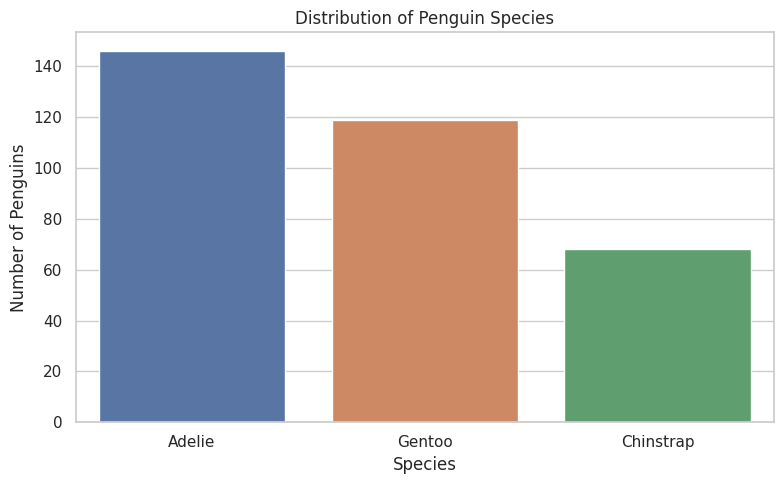

In [10]:
import os

plt.figure(figsize=(8, 5))

sns.countplot(
    data=analysis_df,
    x="species",
    hue="species",
    legend=False
)

plt.title("Distribution of Penguin Species")
plt.xlabel("Species")
plt.ylabel("Number of Penguins")
plt.tight_layout()

# Create the directory if it does not exist
os.makedirs("../visualizations", exist_ok=True)

plt.savefig("../visualizations/species_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

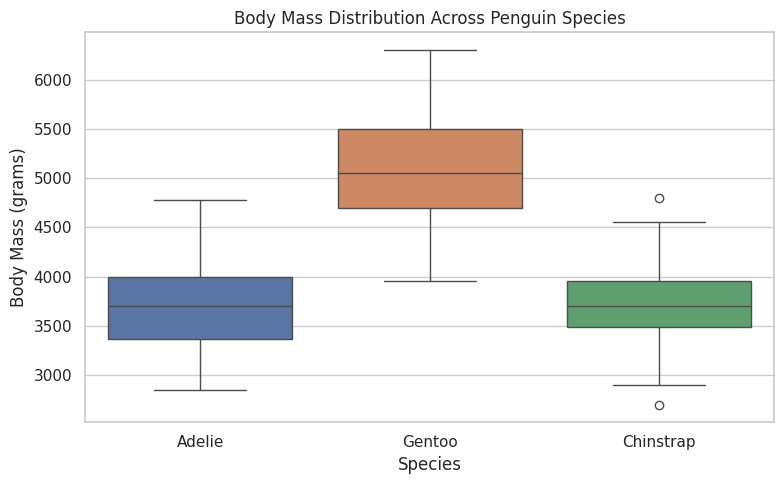

In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=analysis_df,
    x="species",
    y="body_mass_g",
    hue="species",
    legend=False
)

plt.title("Body Mass Distribution Across Penguin Species")
plt.xlabel("Species")
plt.ylabel("Body Mass (grams)")
plt.tight_layout()
plt.show()

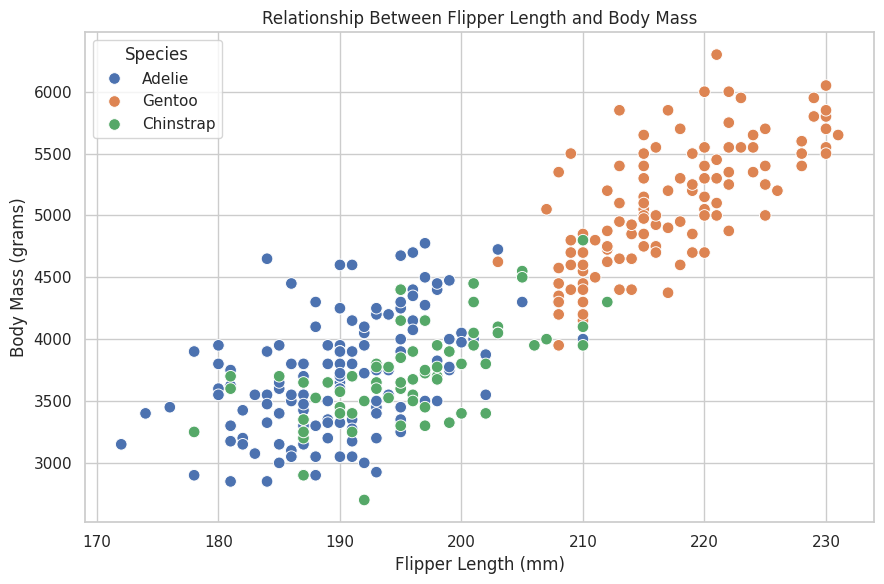

In [12]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=analysis_df,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    s=70
)

plt.title("Relationship Between Flipper Length and Body Mass")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (grams)")
plt.legend(title="Species")
plt.tight_layout()
plt.show()

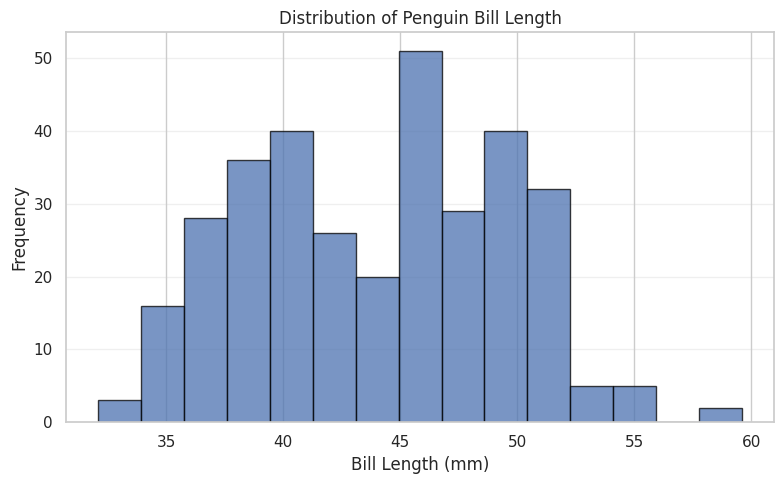

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(
    analysis_df["bill_length_mm"],
    bins=15,
    edgecolor="black",
    alpha=0.75
)

plt.title("Distribution of Penguin Bill Length")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("bill_length_histogram.png", dpi=300)
plt.show()

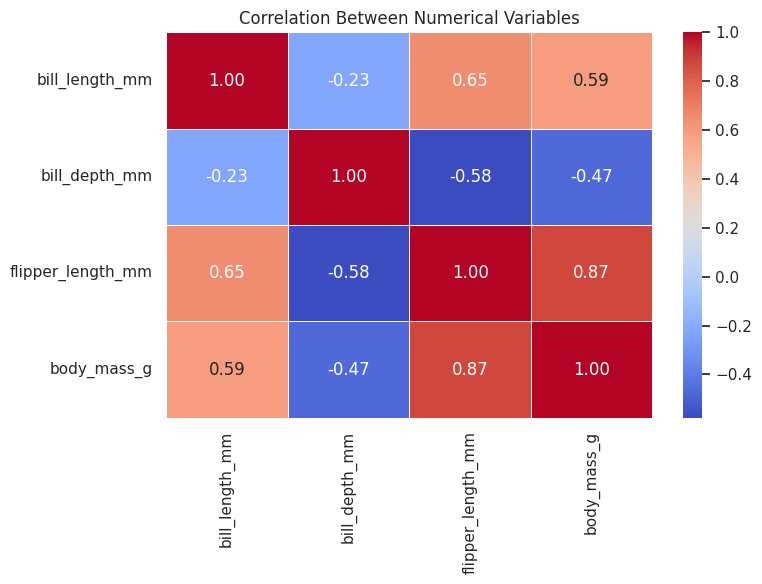

In [14]:
plt.figure(figsize=(8, 6))

correlation = analysis_df[
    numerical_columns
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

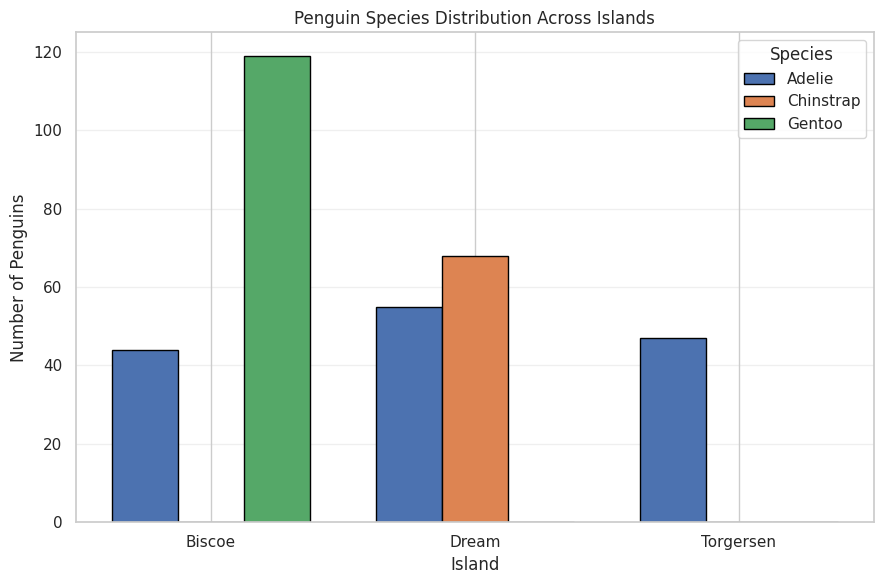

In [15]:
contingency = pd.crosstab(
    analysis_df["island"],
    analysis_df["species"]
)

islands = contingency.index
species = contingency.columns

x = np.arange(len(islands))
width = 0.25

plt.figure(figsize=(9, 6))

for i, s in enumerate(species):
    plt.bar(
        x + i * width,
        contingency[s],
        width,
        label=s,
        edgecolor="black"
    )

plt.xticks(
    x + width,
    islands
)

plt.title("Penguin Species Distribution Across Islands")
plt.xlabel("Island")
plt.ylabel("Number of Penguins")
plt.legend(title="Species")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("species_island_comparison.png", dpi=300)
plt.show()